# Candlestick (OHLC) Chart

**Family:** Change over time &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Change over time:* Emphasise changing trends, from intraday moves to series spanning decades.

## Design purpose

Each period is drawn as a candle. The body spans open to close and the wicks span the low and high, so one mark shows both direction and volatility. It is the standard view of financial price action.

## When to use

- Show open, high, low and close prices of stocks, currencies or commodities
- Read intraperiod volatility and direction together
- Serve trading audiences who expect this convention

## Avoid when

- General audiences who only need the trend (use a line of closing prices)
- There are hundreds of periods (candles become unreadable; aggregate or use a line)

## Alternatives

- Line chart of closing price
- OHLC bar chart
- Fan chart for ranges

## Design tips

- Use color for up/down days; keep wicks thin
- Show volume on a separate panel below, never on a second y-axis

## Example

60 trading days of a synthetic stock, with a volume panel below.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(42)
n = 60
dates = pd.bdate_range("2025-03-03", periods=n)
close = 100 * np.exp(np.cumsum(rng.normal(0.001, 0.018, n)))
open_ = np.r_[100, close[:-1]] * (1 + rng.normal(0, 0.005, n))
high = np.maximum(open_, close) * (1 + rng.uniform(0.002, 0.02, n))
low = np.minimum(open_, close) * (1 - rng.uniform(0.002, 0.02, n))
volume = rng.integers(8e5, 3e6, n)
df = pd.DataFrame({"open": open_, "high": high, "low": low, "close": close,
                   "volume": volume}, index=dates).round(2)
df.head()

,open,high,low,close,volume
2025-03-03,99.16,101.00,98.03,100.65,1818617
2025-03-04,100.48,101.44,98.12,98.88,1311809
2025-03-05,98.96,100.60,97.39,100.33,1535337
2025-03-06,100.62,103.26,99.22,102.14,1967693
2025-03-07,102.51,103.32,97.86,98.72,2483323


### Plot

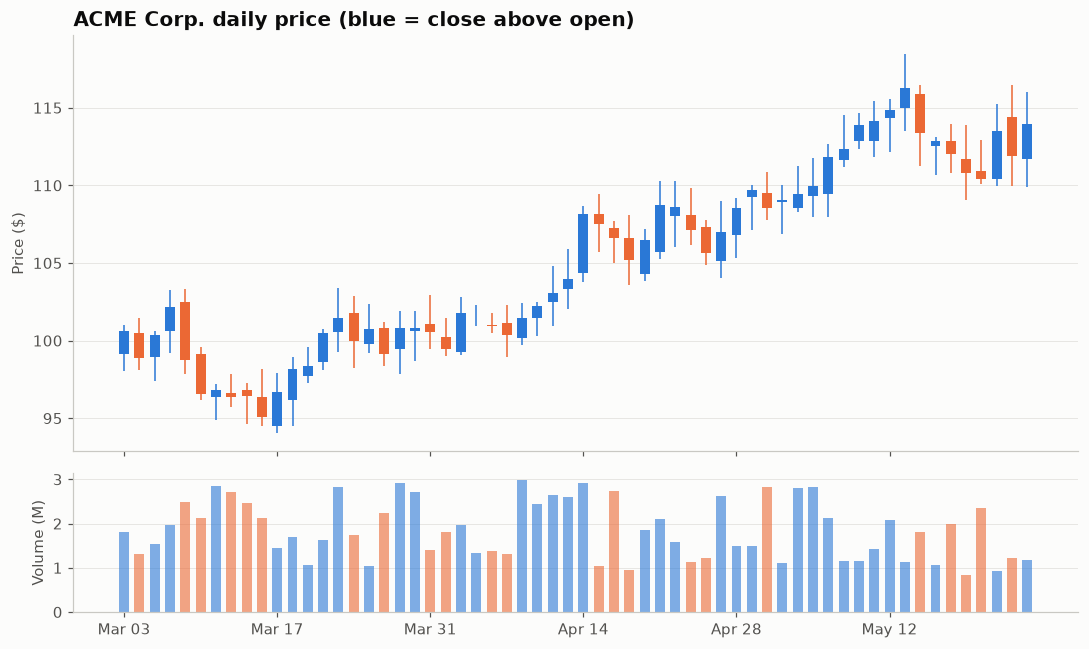

In [3]:
up_color, down_color = PALETTE[0], PALETTE[1]
fig, (ax, axv) = plt.subplots(2, 1, figsize=(10, 6), sharex=True,
                              gridspec_kw={"height_ratios": [3, 1]})
x = np.arange(len(df))
up = df["close"] >= df["open"]
colors = np.where(up, up_color, down_color)
ax.vlines(x, df["low"], df["high"], color=colors, linewidth=1)
ax.bar(x, (df["close"] - df["open"]).abs(), bottom=df[["open", "close"]].min(axis=1),
       color=colors, width=0.65)
axv.bar(x, df["volume"] / 1e6, color=colors, width=0.65, alpha=0.6)
ax.set_ylabel("Price ($)")
axv.set_ylabel("Volume (M)")
ticks = x[::10]
axv.set_xticks(ticks, df.index[::10].strftime("%b %d"))
ax.grid(axis="x", visible=False)
axv.grid(axis="x", visible=False)
ax.set_title("ACME Corp. daily price (blue = close above open)")
fig.tight_layout()
plt.show()

## How to read it

A candle's body runs from open to close: blue means the price rose that day and orange means it fell. Wicks show the day's high and low. Volume sits on its own panel and scale.

---
Standalone script: [`candlestick.py`](candlestick.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)